In [13]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import matplotlib.colors as mcolors

# Stats
import statsmodels.api as sm

In [14]:
from analysis import *

In [15]:
scenarios = ['full_pipeline', 'full_pipeline_trunc', 'no_collapse']

df2 = df.query('scenario.isin(@scenarios)').groupby('scenario').size().reset_index(name = 'count')
df2['label'] = ['Exp. data', 'Exp. data\n(trunc.)', 'Exp. data\n(no cluster)']
df2

,scenario,count,label
0,full_pipeline,277,Exp. data
1,full_pipeline_trunc,200,Exp. data\n(trunc.)
2,no_collapse,332,Exp. data\n(no cluster)


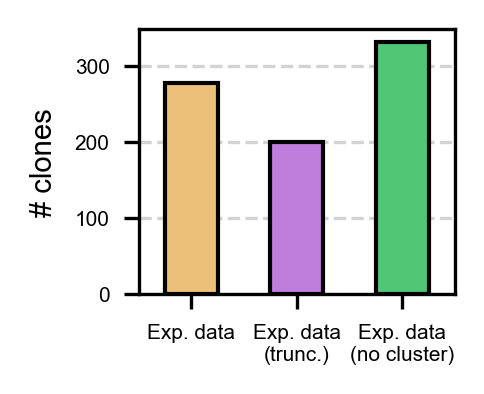

In [17]:
plt.rcParams.update(small_label_settings)
fig, ax = plt.subplots(figsize = (1.5, 1.2), dpi = 300, constrained_layout = True)

palette = {
    'Exp. data': exp_hue,
    'Exp. data\n(no cluster)': no_collapse_hue,
    'Exp. data\n(trunc.)': trunc_hue
}

sns.barplot(
    data=df2,
    x='label',
    y='count',
    hue='label',
    palette=palette,
    legend=False,
    edgecolor='black',
    width=0.5,
    zorder=2,
    ax=ax
)

ax.set_xlabel('')
ax.set_ylabel('# clones')

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis = 'y', zorder=-1)

# plt.tight_layout()

filepath = os.path.join('images', 'clone_count.svg')
plt.savefig(filepath, pad_inches = 0)